# Evaluation of rotational phantom data acquired using a sequence output by SIEMENS vendor PC-MRI sequence

### Necessary imports including mapvbvd to read in SIEMENS raw data_cw

In [2]:
import os
import string
import re
import copy

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as patches
import matplotlib.patheffects as PathEffects
from scipy import ndimage
import cv2

import mapvbvd
from pint import Quantity
# import nibabel as nib

/home/dillin01/rotationalphantom/.venv/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Geometrical data_cw

In [3]:
# phantom radius
r_phan = Quantity(6.3, 'cm')

filetype = '.svg'

### Load raw data

We load the file unsorted, which means we get dimensions [x, coils, others], where others include phase encodings, averages etc. By reshaping according to loop structure, the raw data has the correct dimensions.
Here, we assume a square image dimension and 4 flow encodings.

In [4]:
# Define the path and dataset number

# dir = 1
# venc = 400
# rpm = 500
# data_file_path = r'./data/cw_500_fast.npy'
# filename = Path(data_file_path).stem
# data_cw = np.load(data_file_path)

# dir = 2
# venc = 400
# rpm = 500
# data_file_path = r'./data/ccw_500_fast.npy'
# filename = Path(data_file_path).stem
# data_ccw = np.load(data_file_path)

# ---- BEAT_FQ
dir = 1
venc = 500
rpm = 500
data_file_path = r'meas_MID00176_FID16639_BEAT_FQ_venc500_BW893_dyn16_rpm500_dir1.npy'
filename = Path(data_file_path).stem
data = np.load(data_file_path)
mag = np.abs(data[:, :, 0])
velx = np.angle(data[:, :, 1] / data[:, :, 0])
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])
velx = venc * velx / np.pi
vely = venc * vely / np.pi
velz = venc * velz / np.pi
data_cw = np.stack((mag, velz, velx, vely), axis=-1)

dir = 2
venc = 500
rpm = 500
data_file_path = r'meas_MID00206_FID16669_BEAT_FQ_venc500_BW893_dyn16_rpm500_dir2.npy'
data = np.load(data_file_path)
mag = np.abs(data[:, :, 0])
velx = np.angle(data[:, :, 1] / data[:, :, 0])
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])
velx = venc * velx / np.pi
vely = venc * vely / np.pi
velz = venc * velz / np.pi
data_ccw = np.stack((mag, velz, velx, vely), axis=-1)


# ---- CMRSEQ
# dir = 1
# venc = 500
# rpm = 500
# data_file_path = r'meas_MID00196_FID16659_cmrseq_venc500_echo_BW892_dyn16_rpm500_dir1.npy'
# filename = Path(data_file_path).stem
# data = np.load(data_file_path)
# mag = np.abs(data[:, :, 0])
# velx = np.angle(data[:, :, 1] / data[:, :, 0])
# vely = np.angle(data[:, :, 2] / data[:, :, 0])
# velz = np.angle(data[:, :, 3] / data[:, :, 0])
# velx = venc * velx / np.pi
# vely = venc * vely / np.pi
# velz = venc * velz / np.pi
# data_cw = np.stack((mag, velx, velz, vely), axis=-1)

# dir = 2
# venc = 500
# rpm = 500
# data_file_path = r'meas_MID00226_FID16689_cmrseq_venc500_echo_BW892_dyn16_rpm500_dir2.npy'
# data = np.load(data_file_path)
# mag = np.abs(data[:, :, 0])
# velx = np.angle(data[:, :, 1] / data[:, :, 0])
# vely = np.angle(data[:, :, 2] / data[:, :, 0])
# velz = np.angle(data[:, :, 3] / data[:, :, 0])
# velx = venc * velx / np.pi
# vely = venc * vely / np.pi
# velz = venc * velz / np.pi
# data_ccw = np.stack((mag, velx, velz, vely), axis=-1)

# dir = 1
# venc = 400
# rpm = 500
# data_file_path = r'./data/cw_500.npy'
# filename = Path(data_file_path).stem
# data_cw = np.load(data_file_path)

# dir = 2
# venc = 400
# rpm = 500
# data_file_path = r'./data/ccw_500.npy'
# data_ccw = np.load(data_file_path)
    
venc_lims = (-venc, venc)
venc_ticks = np.arange(-venc, venc*1.1, venc/2)

venc_abs_lims = (0, venc)
venc_abs_ticks = np.arange(0, venc*1.1, venc/2)

diff_fac = 0.05
venc_diff_lims = (-diff_fac*venc, diff_fac*venc)
venc_diff_ticks = np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)

ec_fac = 0.4
venc_ec_lims = (-ec_fac*venc, ec_fac*venc)
# venc_ec_ticks = np.arange(-0.1*venc, venc*0.51, venc/20)
venc_ec_ticks = np.arange(-ec_fac*venc, ec_fac*venc*1.1, ec_fac*venc/2)

In [5]:
print(f'Loaded data with dimensions {data_ccw.shape} and venc {venc}, rpm {rpm}, dir {dir}.')

Loaded data with dimensions (224, 225, 4) and venc 500, rpm 500, dir 2.


### Fit elliptical mask

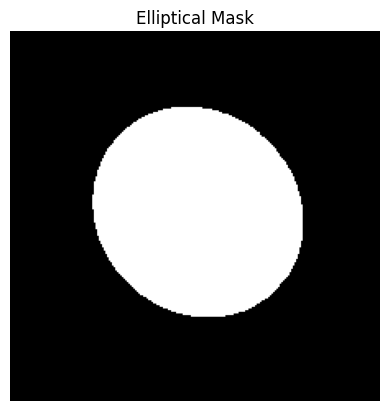

120.48556518554688 133.10301208496094
Eccentricity 0.425
Ratio 0.905


In [22]:
# dicom
mag = data_cw[:, :, 0]

# Normalize magnitude for better contrast
norm_img = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
gray = norm_img.astype(np.uint8)

# Thresholding: You can adjust threshold value depending on your data
_, threshed = cv2.threshold(gray, 70, 255, cv2.THRESH_BINARY)

# Optional: Blur to reduce noise
# threshed = cv2.GaussianBlur(threshed, (1, 1), 2)

# Find contours
cnts, _ = cv2.findContours(threshed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create an empty mask
ellipse_mask = np.zeros_like(mag, dtype=np.uint8)

if cnts:
    # Optionally: choose the largest contour
    cnt = max(cnts, key=cv2.contourArea)

    if len(cnt) >= 5:  # fitEllipse requires at least 5 points
        ellipse = cv2.fitEllipse(cnt)

        # Draw the ellipse onto the mask
        cv2.ellipse(ellipse_mask, ellipse, 255, thickness=-1)

        # Show the result
        plt.imshow(ellipse_mask, cmap='gray', aspect=data_cw.shape[1]/data_cw.shape[0])
        plt.title('Elliptical Mask')
        plt.axis('off')
        plt.show()
    else:
        print("Not enough points to fit an ellipse.")
else:
    print("No contours found.")

ellipse_mask = ellipse_mask / np.max(ellipse_mask[:])

(x, y), (major_axis, minor_axis), angle = ellipse
print(major_axis, minor_axis)
eccentricity = np.sqrt(1 - (major_axis / minor_axis)**2)
print(f'Eccentricity {eccentricity:.3f}')
ratio = major_axis / minor_axis
print(f'Ratio {ratio:.3f}')


### Find center of mass of the image (for the zero velocity case)

In [23]:
centre = np.int64(np.round(ndimage.center_of_mass(ellipse_mask)))
print(centre)

# shift the center by integer offset
offset = centre - tuple(ti//2 for ti in data_cw.shape[0:2])

print(f'Shifting image by {offset[0]} and {offset[1]} pixels.')

# dicom
# offset[0] = -offset[0] - 3
# offset[1] = -offset[1] + 3

# raw
# offset[0] = -offset[0] + 1
# offset[1] = -offset[1] - 1

# offset[0] = 0
# offset[1] = 0

print(offset)
# for plotting hlines and vlines later
center_new = tuple(ti//2 for ti in data_cw.shape[0:2]) - offset

center_img = np.int64(center_new)
# shift center such that coordinates resemble MR coordinate system
center_new = np.int64(center_new - (data_cw.shape[0]/2, data_cw.shape[1]/2))

data_cw = np.take(data_cw, [0, 1, 3, 2], axis=-1)
mag_cw = np.abs(data_cw[:, :, 0])
# dicom
velx_cw = data_cw[:, :, 1]
vely_cw = data_cw[:, :, 2]
velz_cw = data_cw[:, :, 3]

data_ccw = np.take(data_ccw, [0, 1, 3, 2], axis=-1)
mag_ccw = np.abs(data_ccw[:, :, 0])
# dicom
velx_ccw = data_ccw[:, :, 1]
vely_ccw = data_ccw[:, :, 2]
velz_ccw = data_ccw[:, :, 3]

# raw
# velx = np.angle(data[:, :, 1] / data[:, :, 0])
# vely = np.angle(data[:, :, 2] / data[:, :, 0])
# velz = np.angle(data[:, :, 3] / data[:, :, 0])
# velx = venc * velx / np.pi
# vely = venc * vely / np.pi
# velz = venc * velz / np.pi



[109 114]
Shifting image by -3 and 2 pixels.
[-3  2]


In [24]:
cmap = matplotlib.colormaps.get_cmap('twilight')  # viridis is the default colormap for imshow

# Number of colors to sample
N = 256
# Convert to a list of colors
colors = cmap(np.linspace(0, 1, N))

# Shift the colormap by 0.5 (center goes to the ends)
shifted_colors = np.roll(colors, N // 2, axis=0)

# Create a new colormap
shifted_cmap = LinearSegmentedColormap.from_list('shifted_twilight', shifted_colors)

cmap = shifted_cmap
# cmap.set_bad(color='white')
cmap.set_bad(color=cmap(0.5))

In [25]:

ellipse_mask = np.ones_like(ellipse_mask)

## Plot of CW velocities

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


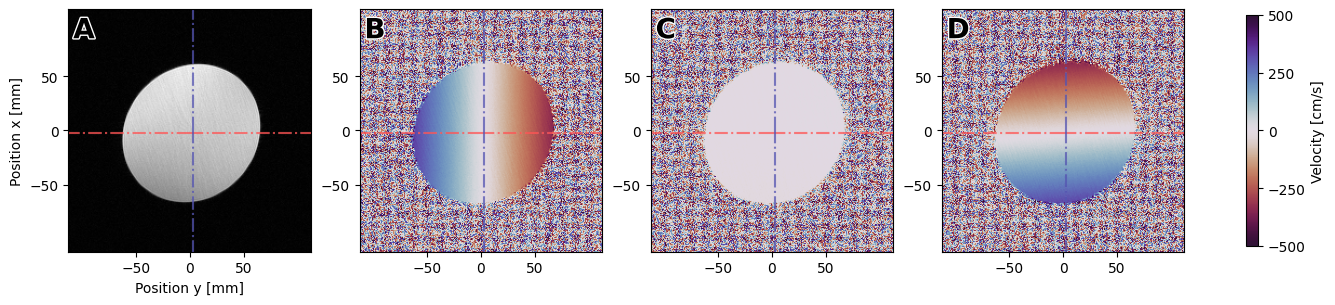

In [26]:
data = data_cw

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mag_cw * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(velx_cw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(vely_cw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow(velz_cw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow1' + filetype)

plt.show()

## Plot of CCW velocities

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


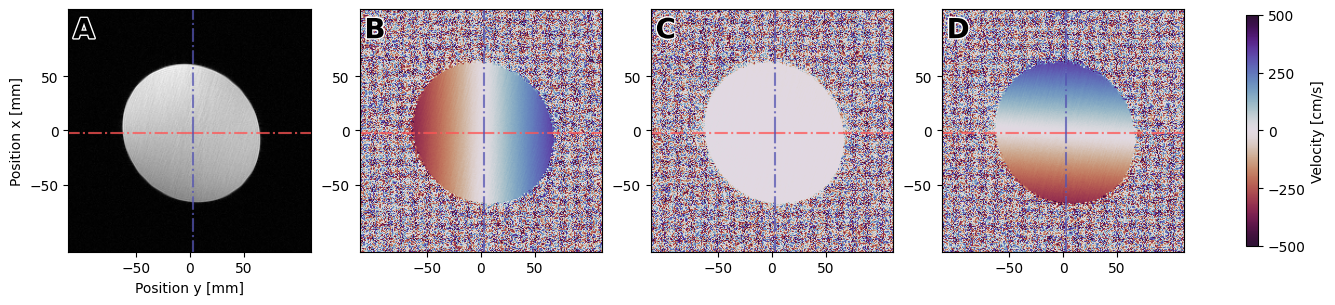

In [27]:
data = data_cw

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mag_ccw * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(velx_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(vely_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow(velz_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow2' + filetype)

plt.show()

### Sum of CW and CCW / 2

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


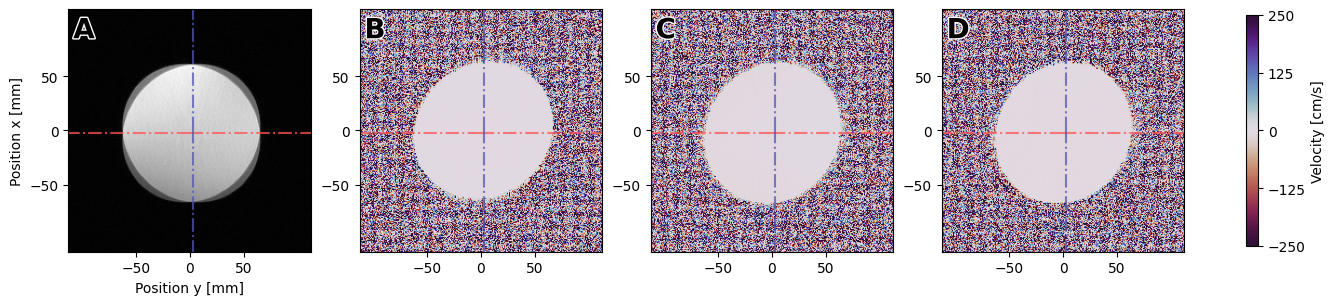

In [28]:
data = data_cw

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow((mag_cw + mag_ccw) / 2 * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

# im1 = axes[1].imshow((velx_cw + velx_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im1 = axes[1].imshow((velx_cw + np.flip(velx_ccw, axis=0)) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

# im2 = axes[2].imshow((vely_cw + vely_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im2 = axes[2].imshow((vely_cw + np.flip(vely_ccw, axis=1)) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

# im3 = axes[3].imshow((velz_cw + velz_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im3 = axes[3].imshow((velz_cw + np.flip(velz_ccw, axis=1)) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow3' + filetype)

plt.show()

### Flipped time reversal of CW and CCW / 2

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


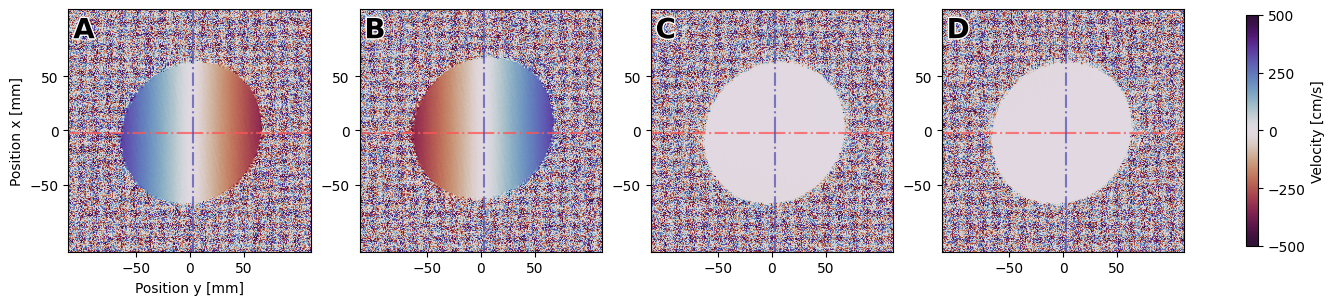

In [29]:
data = data_cw

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

# im1 = axes[1].imshow((velx_cw + velx_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im0 = axes[0].imshow(velx_cw * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_lims[0], vmax=venc_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

# im1 = axes[1].imshow((velx_cw + velx_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im1 = axes[1].imshow(np.flip(velx_ccw, axis=0) * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_lims[0], vmax=venc_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

# im2 = axes[2].imshow((vely_cw + vely_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im2 = axes[2].imshow(vely_cw * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_lims[0], vmax=venc_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

# im3 = axes[3].imshow((velz_cw + velz_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
im3 = axes[3].imshow(np.flip(vely_ccw, axis=1) * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_lims[0], vmax=venc_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow_flip' + filetype)

plt.show()

### Sum of CW and CCW / 2 with mean subtracted

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3
mean x: -0.10135345160961151
mean y: -0.8021208643913269
mean z: -0.8216482400894165


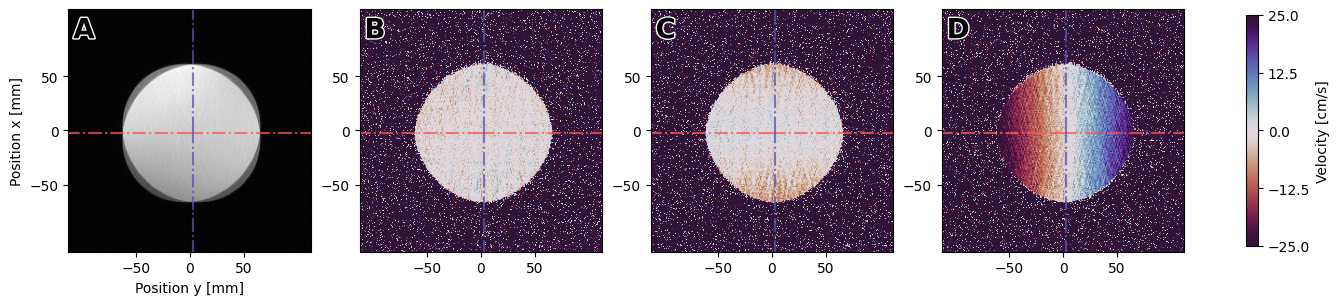

In [30]:
data = data_cw

venc_diff_lims = [x*0.1 for x in venc_diff_lims]
diff_fac = 0.1 * diff_fac

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow((mag_cw + mag_ccw) / 2 * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(((velx_cw + velx_ccw) - np.mean((velx_cw + velx_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])
print(f'mean x: {np.mean((velx_cw + velx_ccw))/2}')

im2 = axes[2].imshow(((vely_cw + vely_ccw) - np.mean((vely_cw + vely_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])
print(f'mean y: {np.mean((vely_cw + vely_ccw))/2}')

im3 = axes[3].imshow(((velz_cw + velz_ccw) - np.mean((velz_cw + velz_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])
print(f'mean z: {np.mean((velz_cw + velz_ccw))/2}')

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow4' + filetype)

plt.show()

venc_diff_lims = [x*10 for x in venc_diff_lims]
diff_fac = 10 * diff_fac


### Sum of CW and CCW / 2 with mean of velz subtracted

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3
mean x: -0.10135345160961151
mean y: -0.8021208643913269
mean z: -0.8216482400894165


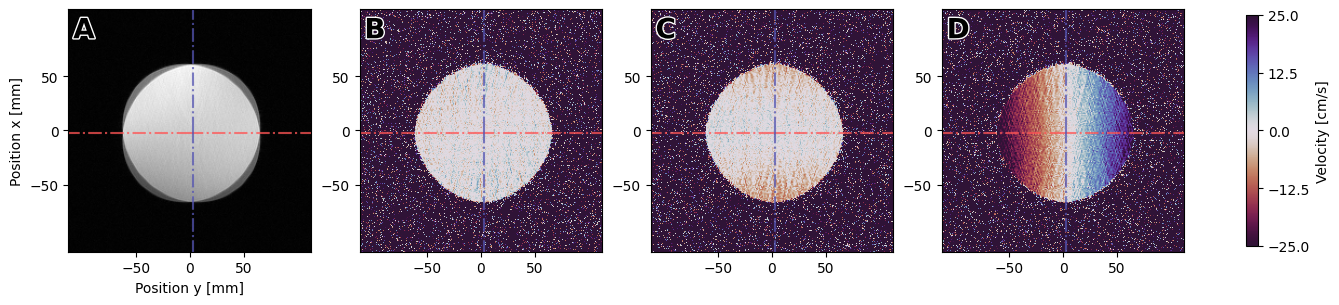

In [31]:
data = data_cw

venc_diff_lims = [x*0.1 for x in venc_diff_lims]
diff_fac = 0.1 * diff_fac

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow((mag_cw + mag_ccw) / 2 * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(((velx_cw + velx_ccw) - np.mean((velz_cw + velz_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])
print(f'mean x: {np.mean((velx_cw + velx_ccw))/2}')

im2 = axes[2].imshow(((vely_cw + vely_ccw) - np.mean((velz_cw + velz_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])
print(f'mean y: {np.mean((vely_cw + vely_ccw))/2}')

im3 = axes[3].imshow(((velz_cw + velz_ccw) - np.mean((velz_cw + velz_ccw))) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])
print(f'mean z: {np.mean((velz_cw + velz_ccw))/2}')

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow5' + filetype)

plt.show()

venc_diff_lims = [x*10 for x in venc_diff_lims]
diff_fac = 10 * diff_fac


## Show acceleration sensitivity after subtraction of ECs

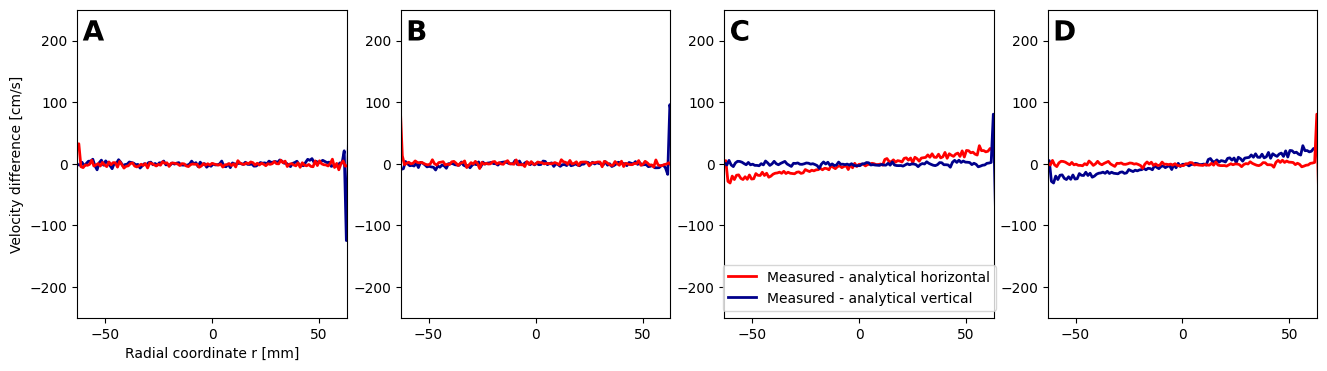

In [32]:
venc_diff_lims = [x for x in venc_diff_lims]
# diff_fac = 0.1 * diff_fac

velx = (((velx_cw + velx_ccw) - np.mean((velx_cw + velx_ccw))) / 2)
vely = (((vely_cw + vely_ccw) - np.mean((vely_cw + vely_ccw))) / 2)
velz = (((velz_cw + velz_ccw) - np.mean((velz_cw + velz_ccw))) / 2)

r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_diff_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[0].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured - analytical  horizontal')
axes[0].set_ylim(venc_diff_lims)
# axes[0].set_yticks(venc_diff_ticks)

axes[1].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[1].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[1].set_ylim(venc_diff_lims)
# axes[1].set_yticks(venc_diff_ticks)

axes[2].plot(r_vec2, velz[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[2].plot(r_vec, velz[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[2].set_ylim(venc_diff_lims)
# axes[2].set_yticks(venc_diff_ticks)

axes[3].plot(r_vec2, velz[center_img[1], :], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[3].plot(r_vec, velz[:, center_img[0]], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[3].set_ylim(venc_diff_lims)
# axes[3].set_yticks(venc_diff_ticks)

axes[0].set_ylabel('Velocity difference [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[2].legend()

plt.savefig(filename + '_acc_veldiff' + filetype)

venc_diff_lims = [x*10 for x in venc_diff_lims]
diff_fac = 10 * diff_fac

0.17590562058245146
1.0203325697038486
[0.0067018 0.5981191]


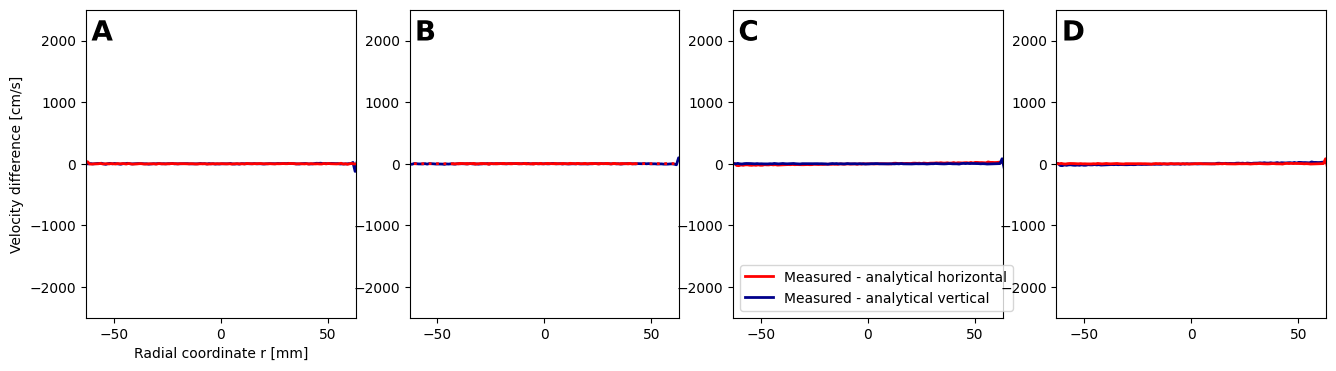

In [33]:
# venc_diff_lims = [0.1*x for x in venc_diff_lims]
# diff_fac = 0.1 * diff_fac

# omit_n_fit = int(np.floor(r_phan.m_as('mm')))
omit_n_fit = 70

velx = (((velx_cw + velx_ccw) - np.mean((velx_cw + velx_ccw))) / 2)
vely = (((vely_cw + vely_ccw) - np.mean((vely_cw + vely_ccw))) / 2)
velz = (((velz_cw + velz_ccw) - np.mean((velz_cw + velz_ccw))) / 2)

r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_diff_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[0].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured - analytical  horizontal')
axes[0].set_ylim(venc_diff_lims)
# axes[0].set_yticks(venc_diff_ticks)

axes[1].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[1].plot(r_vec2[omit_n_fit:-omit_n_fit], vely[center_img[1], omit_n_fit:-omit_n_fit], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[1].set_ylim(venc_diff_lims)

z = np.polyfit(r_vec2[omit_n_fit:-omit_n_fit], vely[center_img[1], omit_n_fit:-omit_n_fit], 1)
p = np.poly1d(z)
print(p(-r_phan.m_as('mm')))
print(p(r_phan.m_as('mm')))
axes[1].plot(r_vec2, p(r_vec2), color='red', linestyle=':', linewidth=2, label='Measured - analytical vertical')
print(z)

# axes[1].set_yticks(venc_diff_ticks)

axes[2].plot(r_vec2, velz[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[2].plot(r_vec, velz[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[2].set_ylim(venc_diff_lims)
# axes[2].set_yticks(venc_diff_ticks)

axes[3].plot(r_vec2, velz[center_img[1], :], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[3].plot(r_vec, velz[:, center_img[0]], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[3].set_ylim(venc_diff_lims)
# axes[3].set_yticks(venc_diff_ticks)

axes[0].set_ylabel('Velocity difference [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[2].legend()

plt.savefig(filename + '_acc_veldiff_fit' + filetype)

# venc_diff_lims = [x*10 for x in venc_diff_lims]
# diff_fac = 10 * diff_fac

### Difference of CW and CCW / 2

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


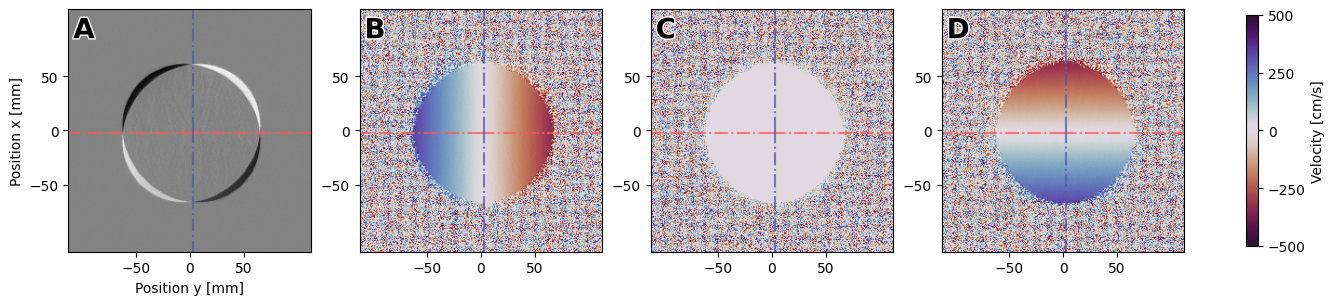

In [34]:
data = data_cw

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow((mag_cw - mag_ccw) / 2, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow((velx_cw - velx_ccw) / 2 , cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(-(vely_cw - vely_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow((velz_cw - velz_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow6' + filetype)

plt.show()

### Difference of CW and CCW / 2 and difference to analytic

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


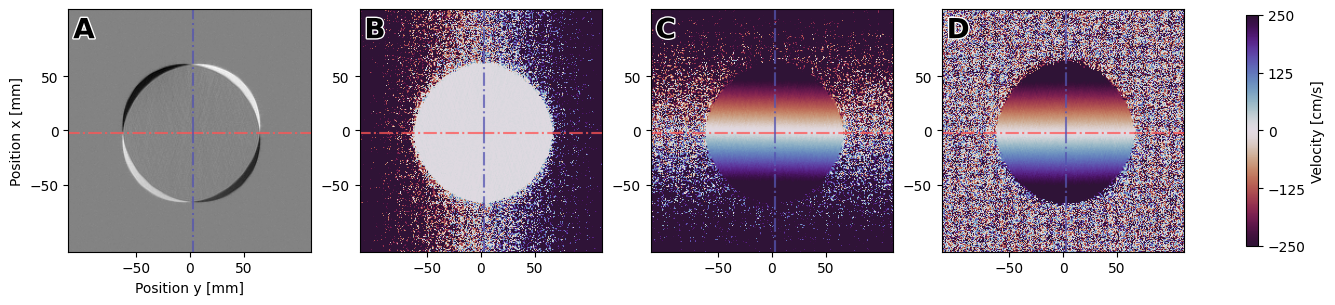

In [35]:
venc_diff_lims = [x*0.1 for x in venc_diff_lims]
diff_fac = 0.1 * diff_fac

data = data_cw

v_analytic_mesh, v_analytic_mesh2 = np.meshgrid(v_analytic, v_analytic2)
v_analytic_mesh = v_analytic_mesh.T


# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow((mag_cw - mag_ccw) / 2, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow((velx_cw - velx_ccw) / 2 + np.rot90(v_analytic_mesh2), cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(-(vely_cw - vely_ccw) / 2 * ellipse_mask + v_analytic_mesh, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow((velz_cw - velz_ccw) / 2 * ellipse_mask, cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(diff_fac*np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow_diff_best_analytic' + filetype)

plt.show()

venc_diff_lims = [x*10 for x in venc_diff_lims]
diff_fac = 10 * diff_fac

In [36]:
print((velx_cw - velx_ccw).shape)

(224, 225)


## Show artefact free line plots

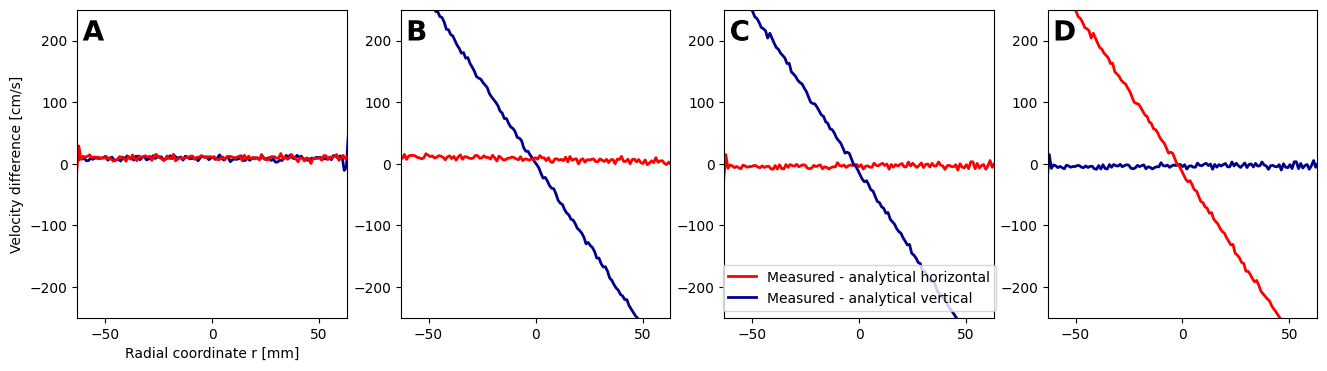

In [37]:
venc_diff_lims = [x*0.1 for x in venc_diff_lims]
diff_fac = 0.1 * diff_fac

# velx = (((velx_cw - velx_ccw) - np.mean((velx_cw - velx_ccw))) / 2)
# vely = -(((vely_cw - vely_ccw) - np.mean((vely_cw - vely_ccw))) / 2)
# velz = (((velz_cw - velz_ccw) - np.mean((velz_cw - velz_ccw))) / 2)

velx = (velx_cw - velx_ccw) / 2 + np.rot90(v_analytic_mesh2)
vely = -(vely_cw - vely_ccw) / 2 * ellipse_mask + v_analytic_mesh
velz = (velz_cw - velz_ccw) / 2 * ellipse_mask

r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_diff_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[0].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured - analytical  horizontal')
axes[0].set_ylim(venc_diff_lims)
# axes[0].set_yticks(venc_diff_ticks)

axes[1].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[1].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[1].set_ylim(venc_diff_lims)
# axes[1].set_yticks(venc_diff_ticks)

axes[2].plot(r_vec2, velz[center_img[1], :], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[2].plot(r_vec, velz[:, center_img[0]], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[2].set_ylim(venc_diff_lims)
# axes[2].set_yticks(venc_diff_ticks)

axes[3].plot(r_vec2, velz[center_img[1], :], color='darkblue', linewidth=2, label='Measured - analytical vertical')
axes[3].plot(r_vec, velz[:, center_img[0]], color='red', linewidth=2, label='Measured - analytical horizontal')
axes[3].set_ylim(venc_diff_lims)
# axes[3].set_yticks(venc_diff_ticks)

axes[0].set_ylabel('Velocity difference [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[2].legend()

plt.savefig(filename + '_acc_veldiff_line' + filetype)

venc_diff_lims = [x*10 for x in venc_diff_lims]
diff_fac = 10 * diff_fac

Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


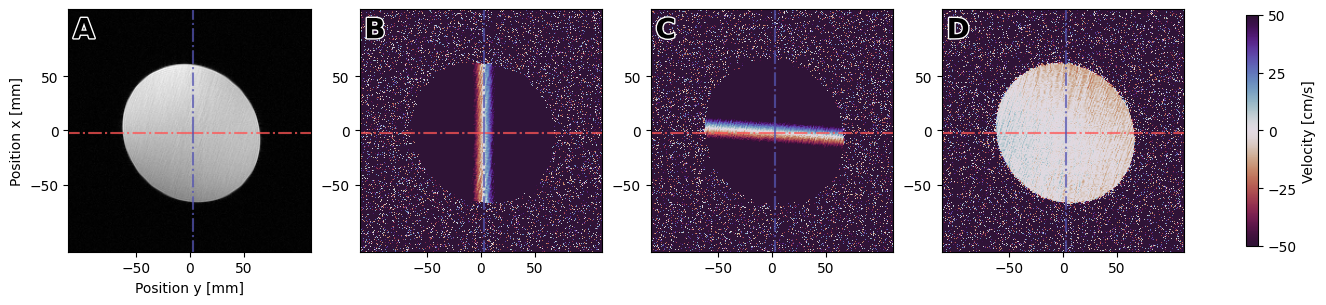

In [45]:
## Plot of CCW velocities
data = data_cw

diff_fac2 = 0.1

# vel_mag = np.sqrt(velx**2 + vely**2)

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mag_ccw * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(velx_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-diff_fac2*venc, vmax=diff_fac2*venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[3].imshow(vely_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-diff_fac2*venc, vmax=diff_fac2*venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[2].imshow(velz_ccw * ellipse_mask, cmap=cmap, origin='lower', vmin=-diff_fac2*venc, vmax=diff_fac2*venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-diff_fac2*venc, diff_fac2*venc*1.1, diff_fac2*venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
    axis.set_xticks((-50, 0, 50))
    axis.set_yticks((-50, 0, 50))
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig(filename + '_imshow_clamped' + filetype)

plt.show()